In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Membuat koneksi database
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan foreign key
cursor.execute("PRAGMA foreign_keys = ON")

# Membuat tabel buku
cursor.execute("""
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
)
""")

# Membuat tabel anggota
cursor.execute("""
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT NOT NULL
)
""")

# Membuat tabel peminjaman
cursor.execute("""
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
""")

conn.commit()

print("Database dan tabel berhasil dibuat!")

Database dan tabel berhasil dibuat!


In [2]:
# Menambahkan 5 data buku
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    ('Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    ('Filosofi Teras', 'Henry Manampiring', 2018),
    ('Laut Bercerita', 'Leila S. Chudori', 2017)
]

cursor.executemany("""
INSERT INTO buku (judul, penulis, tahun)
VALUES (?, ?, ?)
""", data_buku)

# Menambahkan 3 data anggota
data_anggota = [
    ('Andi Saputra', 'andi@gmail.com'),
    ('Budi Santoso', 'budi@gmail.com'),
    ('Citra Lestari', 'citra@gmail.com')
]

cursor.executemany("""
INSERT INTO anggota (nama, email)
VALUES (?, ?)
""", data_anggota)

conn.commit()

print("5 data buku dan 3 data anggota berhasil ditambahkan!")

5 data buku dan 3 data anggota berhasil ditambahkan!


In [3]:
pd.read_sql_query("SELECT * FROM buku", conn)

,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi Manusia,Pramoedya Ananta Toer,1980
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Filosofi Teras,Henry Manampiring,2018
4,5,Laut Bercerita,Leila S. Chudori,2017


In [4]:
pd.read_sql_query("SELECT * FROM anggota", conn)

,id,nama,email
0,1,Andi Saputra,andi@gmail.com
1,2,Budi Santoso,budi@gmail.com
2,3,Citra Lestari,citra@gmail.com


In [5]:
data_peminjaman = [
    (1, 1, '2026-11-01', '2026-11-07'),
    (2, 2, '2026-11-03', '2026-11-10'),
    (3, 3, '2026-11-05', None),
    (1, 4, '2026-11-08', '2026-11-15')
]

cursor.executemany("""
INSERT INTO peminjaman
(id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?)
""", data_peminjaman)

conn.commit()

print("4 transaksi peminjaman berhasil ditambahkan!")

4 transaksi peminjaman berhasil ditambahkan!


In [6]:
query_join = """
SELECT
    peminjaman.id AS id_peminjaman,
    anggota.nama AS nama_anggota,
    buku.judul AS judul_buku,
    peminjaman.tgl_pinjam,
    peminjaman.tgl_kembali
FROM peminjaman
JOIN anggota
    ON peminjaman.id_anggota = anggota.id
JOIN buku
    ON peminjaman.id_buku = buku.id
ORDER BY peminjaman.id
"""

df_peminjaman = pd.read_sql_query(query_join, conn)

display(df_peminjaman)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
1,2,Budi Santoso,Bumi Manusia,2026-11-03,2026-11-10
2,3,Citra Lestari,Negeri 5 Menara,2026-11-05,None
3,4,Andi Saputra,Filosofi Teras,2026-11-08,2026-11-15


In [7]:
query_group = """
SELECT
    anggota.nama AS nama_anggota,
    COUNT(peminjaman.id) AS jumlah_buku_dipinjam
FROM anggota
LEFT JOIN peminjaman
    ON anggota.id = peminjaman.id_anggota
GROUP BY anggota.id, anggota.nama
ORDER BY jumlah_buku_dipinjam DESC
"""

df_group = pd.read_sql_query(query_group, conn)

display(df_group)

,nama_anggota,jumlah_buku_dipinjam
0,Andi Saputra,2
1,Budi Santoso,1
2,Citra Lestari,1


In [8]:
# Mengambil data hasil query SQL ke dalam DataFrame
df = pd.read_sql_query(query_join, conn)

# Menampilkan DataFrame
display(df)

# Melihat informasi DataFrame
print("Informasi DataFrame:")
df.info()

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
1,2,Budi Santoso,Bumi Manusia,2026-11-03,2026-11-10
2,3,Citra Lestari,Negeri 5 Menara,2026-11-05,None
3,4,Andi Saputra,Filosofi Teras,2026-11-08,2026-11-15


Informasi DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_peminjaman  4 non-null      int64 
 1   nama_anggota   4 non-null      object
 2   judul_buku     4 non-null      object
 3   tgl_pinjam     4 non-null      object
 4   tgl_kembali    3 non-null      object
dtypes: int64(1), object(4)
memory usage: 292.0+ bytes


In [9]:
# Mengubah kolom tanggal menjadi format datetime
df['tgl_pinjam'] = pd.to_datetime(df['tgl_pinjam'])
df['tgl_kembali'] = pd.to_datetime(df['tgl_kembali'])

# Mengambil tanggal hari ini
tanggal_sekarang = pd.Timestamp.today().normalize()

# Menghitung durasi peminjaman
df['durasi_pinjam'] = (
    df['tgl_kembali'].fillna(tanggal_sekarang) - df['tgl_pinjam']
).dt.days

# Menambahkan status peminjaman
df['status'] = df['tgl_kembali'].apply(
    lambda x: 'Sudah Dikembalikan' if pd.notna(x)
    else 'Belum Dikembalikan'
)

# Menampilkan hasil eksplorasi
display(df)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_pinjam,status
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07,6,Sudah Dikembalikan
1,2,Budi Santoso,Bumi Manusia,2026-11-03,2026-11-10,7,Sudah Dikembalikan
2,3,Citra Lestari,Negeri 5 Menara,2026-11-05,NaT,14,Belum Dikembalikan
3,4,Andi Saputra,Filosofi Teras,2026-11-08,2026-11-15,7,Sudah Dikembalikan


In [10]:
print("Statistik Durasi Peminjaman:")
print(df['durasi_pinjam'].describe())

Statistik Durasi Peminjaman:
count     4.000000
mean      8.500000
std       3.696846
min       6.000000
25%       6.750000
50%       7.000000
75%       8.750000
max      14.000000
Name: durasi_pinjam, dtype: float64


In [11]:
# Menghitung jumlah transaksi per anggota
pola_peminjaman = df.groupby('nama_anggota').size()

print("Pola Peminjaman Berdasarkan Anggota:")
display(pola_peminjaman.reset_index(name='jumlah_peminjaman'))

# Menghitung status peminjaman
print("Status Peminjaman:")
print(df['status'].value_counts())

Pola Peminjaman Berdasarkan Anggota:


,nama_anggota,jumlah_peminjaman
0,Andi Saputra,2
1,Budi Santoso,1
2,Citra Lestari,1


Status Peminjaman:
status
Sudah Dikembalikan    3
Belum Dikembalikan    1
Name: count, dtype: int64


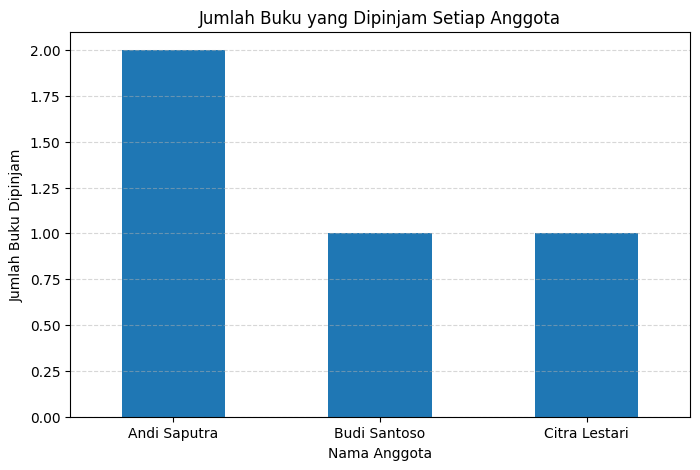

In [12]:
# Mengelompokkan jumlah peminjaman berdasarkan anggota
jumlah_pinjam = df.groupby('nama_anggota').size()

# Membuat diagram batang
plt.figure(figsize=(8, 5))

jumlah_pinjam.plot(kind='bar')

plt.title('Jumlah Buku yang Dipinjam Setiap Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Buku Dipinjam')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

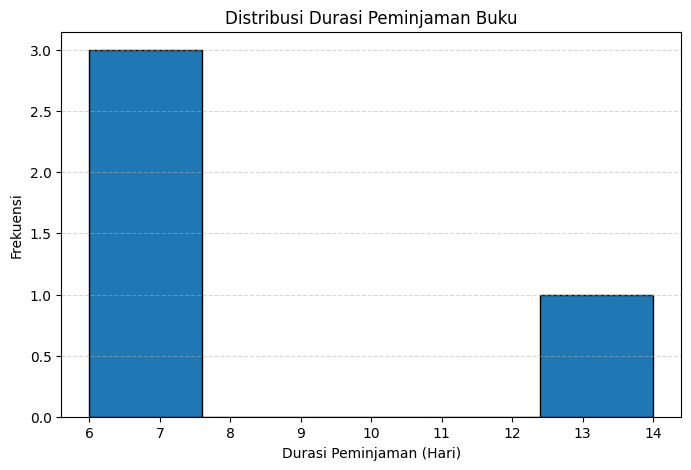

In [13]:
# Membuat histogram durasi peminjaman
plt.figure(figsize=(8, 5))

plt.hist(df['durasi_pinjam'], bins=5, edgecolor='black')

plt.title('Distribusi Durasi Peminjaman Buku')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

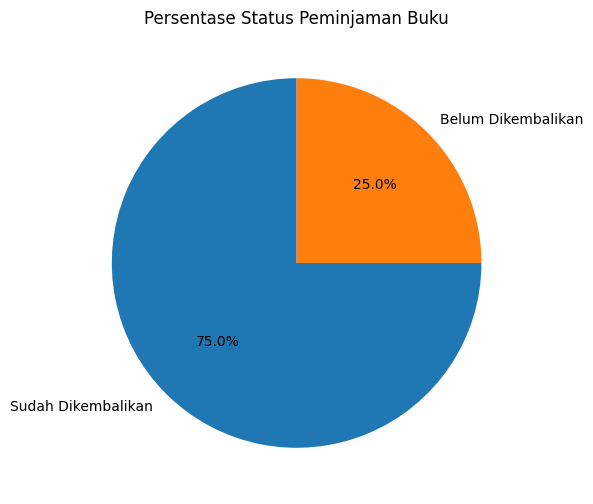

In [14]:
# Menghitung jumlah berdasarkan status
status_count = df['status'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    status_count,
    labels=status_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Persentase Status Peminjaman Buku')
plt.show()